In [12]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/german-credit/german_credit_data.csv


In [13]:
!pip install lime

In [14]:
# ============================================
# CELL 1: INSTALL AND IMPORT LIBRARIES
# ============================================

import sys
import subprocess
import importlib.util

# Install LIME only if unavailable
if importlib.util.find_spec("lime") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "lime",
        "--quiet"
    ])

import os
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from lime.lime_tabular import LimeTabularExplainer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = "/kaggle/working/RSA_Practical_Outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True

print("All libraries imported successfully!")
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("SHAP:", shap.__version__)
print("Output directory:", OUTPUT_DIR)

All libraries imported successfully!
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas: 2.3.3
SHAP: 0.54.1
Output directory: /kaggle/working/RSA_Practical_Outputs


In [15]:
# ============================================
# CELL 2: DATASET DISCOVERY
# ============================================

all_files = glob.glob(
    "/kaggle/input/**/*",
    recursive=True
)

all_files = [
    f for f in all_files
    if os.path.isfile(f)
]

print("AVAILABLE INPUT FILES")
print("=" * 70)

for path in all_files:
    print(path)

if not all_files:
    raise FileNotFoundError(
        "No Kaggle input files found. Add the UCI German Credit dataset."
    )

# Find possible original UCI files
uci_candidates = [
    f for f in all_files
    if os.path.basename(f).lower() in [
        "german.data",
        "german.data-numeric",
        "german_credit.csv",
        "german_credit_data.csv"
    ]
]

print("\nPotential German Credit files:")
for path in uci_candidates:
    print(path)

AVAILABLE INPUT FILES
/kaggle/input/datasets/uciml/german-credit/german_credit_data.csv

Potential German Credit files:
/kaggle/input/datasets/uciml/german-credit/german_credit_data.csv


In [17]:

# CELL 3: LOAD THE CORRECT UCI GERMAN CREDIT DATASET

import os
import glob
import pandas as pd
import numpy as np
from pathlib import Path

# Original UCI Statlog German Credit column names
UCI_COLUMNS = [
    "checking_status",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_status",
    "employment",
    "installment_rate",
    "personal_status",
    "other_parties",
    "residence_since",
    "property_magnitude",
    "age",
    "other_payment_plans",
    "housing",
    "existing_credits",
    "job",
    "num_dependents",
    "own_telephone",
    "foreign_worker",
    "class"
]

df = None
dataset_source = None

# --------------------------------------------------
# 1. Search Kaggle input directories for german.data
# --------------------------------------------------
search_paths = glob.glob(
    "/kaggle/input/**/german.data",
    recursive=True
)

for file_path in search_paths:
    try:
        temp = pd.read_csv(
            file_path,
            sep=r"\s+",
            header=None,
            names=UCI_COLUMNS
        )

        if temp.shape == (1000, 21):
            df = temp
            dataset_source = file_path
            break

    except Exception as e:
        print("Could not read:", file_path, "|", e)

# --------------------------------------------------
# 2. Search for an already labelled CSV
# --------------------------------------------------
if df is None:
    csv_files = glob.glob(
        "/kaggle/input/**/*.csv",
        recursive=True
    )

    for file_path in csv_files:
        try:
            temp = pd.read_csv(file_path)
            temp.columns = [
                str(c).strip().lower() for c in temp.columns
            ]

            possible_targets = [
                "class", "risk", "credit_risk",
                "target", "label", "default"
            ]

            target_col = next(
                (c for c in possible_targets if c in temp.columns),
                None
            )

            if target_col is not None:
                df = temp
                dataset_source = file_path
                df.rename(columns={target_col: "class"}, inplace=True)
                break

        except Exception:
            continue

# --------------------------------------------------
# 3. Download original UCI data if not found
# --------------------------------------------------
if df is None:
    import urllib.request

    uci_url = (
        "https://archive.ics.uci.edu/"
        "ml/machine-learning-databases/"
        "statlog/german/german.data"
    )

    download_path = "/kaggle/working/german.data"

    try:
        print("Trying to download the original UCI dataset...")

        urllib.request.urlretrieve(uci_url, download_path)

        temp = pd.read_csv(
            download_path,
            sep=r"\s+",
            header=None,
            names=UCI_COLUMNS
        )

        if temp.shape == (1000, 21):
            df = temp
            dataset_source = download_path

    except Exception as e:
        print("Automatic download failed:", str(e))

# --------------------------------------------------
# 4. Validate dataset
# --------------------------------------------------
if df is None:
    raise FileNotFoundError(
        "The correct German Credit dataset was not found.\n"
        "Your current 9-column CSV has no target column.\n\n"
        "In Kaggle, click Add Input and add the original "
        "UCI Statlog German Credit dataset containing "
        "the file 'german.data', or enable Internet "
        "and rerun this cell."
    )

if "class" not in df.columns:
    raise ValueError("Target column 'class' is missing.")

if len(df) != 1000:
    raise ValueError(
        f"Expected 1000 rows, but found {len(df)} rows."
    )

# --------------------------------------------------
# 5. Convert target: 1 = good, 2 = bad
#    Required practical convention: bad = 1
# --------------------------------------------------
df["class"] = pd.to_numeric(df["class"], errors="coerce")

if not set(df["class"].dropna().unique()).issubset({1, 2}):
    raise ValueError(
        "Unexpected target values. Expected UCI class values 1 and 2."
    )

df["class"] = df["class"].map({
    1: 0,  # Good credit
    2: 1   # Bad credit
})

if df["class"].isna().any():
    raise ValueError("Missing or invalid target values detected.")

print("Dataset loaded successfully!")
print("Source:", dataset_source)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nTarget distribution:")
print(df["class"].value_counts())
print("\nFirst five rows:")
display(df.head())


Trying to download the original UCI dataset...
Dataset loaded successfully!
Source: /kaggle/working/german.data
Dataset shape: (1000, 21)

Columns:
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_rate', 'personal_status', 'other_parties', 'residence_since', 'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker', 'class']

Target distribution:
class
0    700
1    300
Name: count, dtype: int64

First five rows:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


In [20]:
# ============================================
# CELL 4: TARGET AND FEATURE PREPARATION
# ============================================

import pandas as pd
import numpy as np

# Identify target column
target_candidates = [
    "class", "risk", "target", "label",
    "credit_risk", "creditability"
]

target_column = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_column is None:
    raise ValueError("Target column is missing!")

# Standard binary encoding for this dataset
# 0 = Good credit
# 1 = Bad credit

target_mapping = {
    0: 0,
    1: 1,
    "0": 0,
    "1": 1,
    "good": 0,
    "bad": 1
}

y = df[target_column].map(target_mapping)

if y.isnull().any():
    raise ValueError(
        "Unexpected or missing target labels detected!"
    )

y = y.astype(int)

# Initialize features
X_raw = df.drop(columns=[target_column]).copy()

print("=" * 55)
print("DATASET INITIALIZATION SUCCESSFUL")
print("=" * 55)

print("\nTarget column:", target_column)
print("Feature shape:", X_raw.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print("Good Credit (0):", (y == 0).sum())
print("Bad Credit (1):", (y == 1).sum())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nFeatures:")
print(X_raw.columns.tolist())

print("\nDataset ready for training!")

display(X_raw.head())

DATASET INITIALIZATION SUCCESSFUL

Target column: class
Feature shape: (1000, 20)
Target shape: (1000,)

Target distribution:
Good Credit (0): 700
Bad Credit (1): 300

Target percentages:
class
0    70.0
1    30.0
Name: proportion, dtype: float64

Features:
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_rate', 'personal_status', 'other_parties', 'residence_since', 'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker']

Dataset ready for training!


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [21]:
# ============================================
# CELL 5: FEATURE IDENTIFICATION
# ============================================

categorical_columns = X_raw.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_columns = [
    col for col in X_raw.columns
    if col not in categorical_columns
]

feature_names = X_raw.columns.tolist()

print("Categorical attributes:")
print(categorical_columns)

print("\nNumerical attributes:")
print(numerical_columns)

print("\nTotal features:", len(feature_names))

if len(feature_names) == 0:
    raise ValueError("No predictor features found!")

print("\nFeature identification completed!")

Categorical attributes:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Numerical attributes:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Total features: 20

Feature identification completed!


In [22]:
# ============================================
# CELL 6: TRAIN TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_raw))
print("Testing samples:", len(X_test_raw))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

print("\nStratified split completed!")

Training samples: 800
Testing samples: 200

Training distribution:
class
0    560
1    240
Name: count, dtype: int64

Testing distribution:
class
0    140
1     60
Name: count, dtype: int64

Stratified split completed!


In [23]:
# ============================================
# CELL 7: DATA PREPROCESSING
# ============================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

# Numerical imputation
if numerical_columns:

    num_imputer = SimpleImputer(strategy="median")

    X_train[numerical_columns] = num_imputer.fit_transform(
        X_train[numerical_columns]
    )

    X_test[numerical_columns] = num_imputer.transform(
        X_test[numerical_columns]
    )

# Categorical imputation and encoding
ordinal_encoder = None
cat_imputer = None

if categorical_columns:

    cat_imputer = SimpleImputer(strategy="most_frequent")

    train_cat = cat_imputer.fit_transform(
        X_train[categorical_columns]
    )

    test_cat = cat_imputer.transform(
        X_test[categorical_columns]
    )

    ordinal_encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    train_encoded = ordinal_encoder.fit_transform(train_cat)
    test_encoded = ordinal_encoder.transform(test_cat)

    X_train[categorical_columns] = train_encoded
    X_test[categorical_columns] = test_encoded

# Convert everything to numeric
X_train = X_train.astype(float)
X_test = X_test.astype(float)

# Preserve feature names
feature_names = X_train.columns.tolist()

print("Preprocessing completed successfully!")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nMissing values in training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum().sum())

display(X_train.head())

Preprocessing completed successfully!

Training data shape: (800, 20)
Testing data shape: (200, 20)

Missing values in training data:
0

Missing values in testing data:
0


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
828,0.0,36.0,2.0,1.0,8335.0,4.0,4.0,3.0,2.0,0.0,4.0,3.0,47.0,2.0,2.0,1.0,2.0,1.0,0.0,0.0
997,3.0,12.0,2.0,4.0,804.0,0.0,4.0,4.0,2.0,0.0,4.0,2.0,38.0,2.0,1.0,1.0,2.0,1.0,0.0,0.0
148,0.0,36.0,4.0,3.0,5371.0,0.0,2.0,3.0,2.0,2.0,2.0,1.0,28.0,2.0,1.0,2.0,2.0,1.0,0.0,0.0
735,1.0,36.0,1.0,5.0,3990.0,4.0,1.0,3.0,1.0,0.0,2.0,3.0,29.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
130,1.0,48.0,2.0,0.0,8487.0,4.0,3.0,1.0,1.0,0.0,2.0,2.0,24.0,2.0,1.0,1.0,2.0,1.0,0.0,0.0


In [26]:
# ============================================
# CELL 8: RANDOM FOREST MODEL
# ============================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

bad_class_index = list(rf_model.classes_).index(1)

y_prob = rf_model.predict_proba(X_test)[:, bad_class_index]

print("Random Forest model trained successfully!")
print("Trees:", 200)
print("Maximum depth:", 8)

Random Forest model trained successfully!
Trees: 200
Maximum depth: 8


In [27]:
# ============================================
# CELL 9: MODEL PERFORMANCE
# ============================================

from sklearn.metrics import accuracy_score, roc_auc_score

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\nMODEL PERFORMANCE")
print("-" * 45)

print(f"Test accuracy : {accuracy:.2f}")
print(f"ROC-AUC       : {roc_auc:.2f}")


MODEL PERFORMANCE
---------------------------------------------
Test accuracy : 0.77
ROC-AUC       : 0.81


In [28]:
# ============================================
# CELL 10: SHAP EXPLANATION
# ============================================

import shap
import numpy as np
import matplotlib.pyplot as plt

shap_explainer = shap.TreeExplainer(rf_model)

raw_shap_values = shap_explainer.shap_values(X_test)

n_samples, n_features = X_test.shape

if isinstance(raw_shap_values, list):

    shap_values_bad = np.asarray(
        raw_shap_values[bad_class_index]
    )

else:

    sv = np.asarray(raw_shap_values)

    if sv.ndim == 2:
        shap_values_bad = sv

    elif sv.ndim == 3:

        if sv.shape == (n_samples, n_features, 2):
            shap_values_bad = sv[:, :, bad_class_index]

        elif sv.shape == (2, n_samples, n_features):
            shap_values_bad = sv[bad_class_index]

        elif sv.shape == (n_samples, 2, n_features):
            shap_values_bad = sv[:, bad_class_index, :]

        else:
            raise ValueError(
                f"Unexpected SHAP shape: {sv.shape}"
            )

    else:
        raise ValueError("Unsupported SHAP output format.")

print("SHAP TreeExplainer initialized successfully!")

SHAP TreeExplainer initialized successfully!


In [29]:
# ============================================
# CELL 11: GLOBAL SHAP FEATURE IMPORTANCE
# ============================================

mean_abs_shap = np.abs(
    shap_values_bad
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    "Mean_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance.index += 1

top_5_features = shap_importance.head(5)

print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("-" * 55)

print(f"{'RANK':<6}{'FEATURE':<25}{'MEAN|SHAP|':>12}")
print("-" * 55)

for rank, row in top_5_features.iterrows():

    print(
        f"{rank:<6}"
        f"{row['Feature']:<25}"
        f"{row['Mean_SHAP']:>12.3f}"
    )


GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
-------------------------------------------------------
RANK  FEATURE                    MEAN|SHAP|
-------------------------------------------------------
1     checking_status                 0.087
2     duration                        0.041
3     savings_status                  0.039
4     credit_amount                   0.026
5     credit_history                  0.026


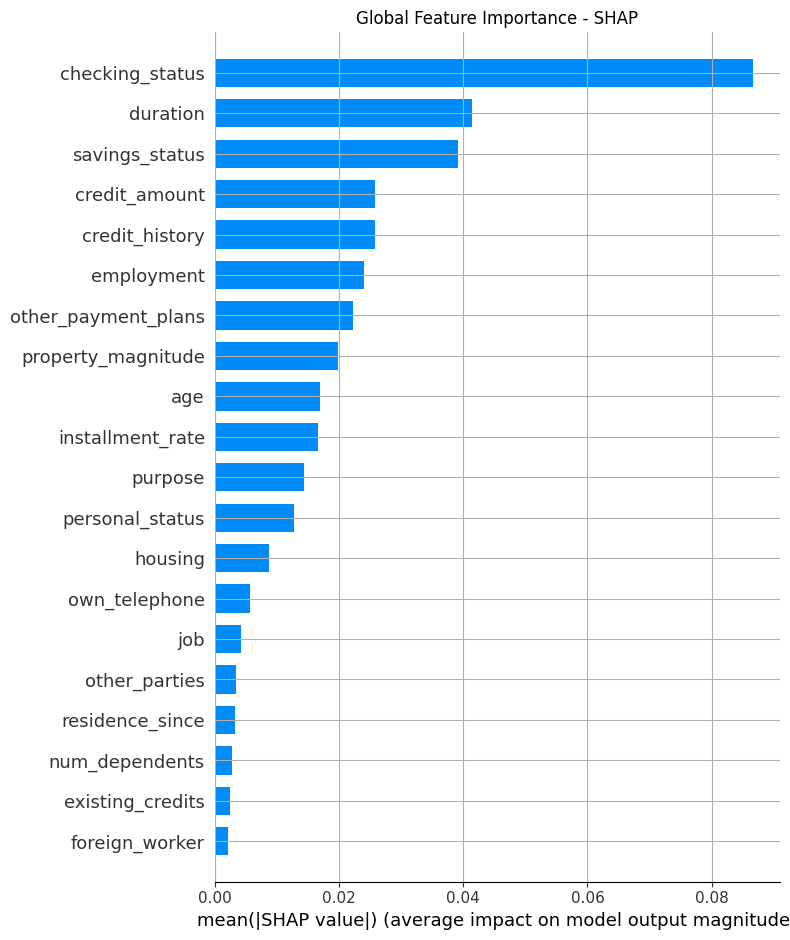

Plot saved : shap_summary.png


In [30]:
# ============================================
# CELL 12: SHAP SUMMARY PLOT
# ============================================

import os

OUTPUT_DIR = "/kaggle/working/RSA_Practical_Outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.figure()

shap.summary_plot(
    shap_values_bad,
    X_test,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title("Global Feature Importance - SHAP")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "shap_summary.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Plot saved : shap_summary.png")

In [31]:
# ============================================
# CELL 13: SELECT REJECTED APPLICANT
# ============================================

rejected_positions = np.where(y_pred == 1)[0]

if len(rejected_positions) == 0:

    raise ValueError(
        "No rejected applicant was predicted. "
        "Cannot generate the required rejected-applicant "
        "explanation without a rejected prediction."
    )

# Select rejected applicant with highest bad-credit probability
applicant_position = int(
    rejected_positions[
        np.argmax(y_prob[rejected_positions])
    ]
)

applicant_index = X_test.index[applicant_position]

applicant = X_test.iloc[applicant_position]

applicant_original = X_test_raw.iloc[applicant_position]

applicant_probability = float(
    y_prob[applicant_position]
)

print("Rejected applicant selected successfully!")

Rejected applicant selected successfully!


In [32]:
# ============================================
# CELL 14: LOCAL SHAP TOP 3
# ============================================

local_shap_values = shap_values_bad[applicant_position]

local_shap_df = pd.DataFrame({

    "Feature": feature_names,

    "Value": applicant_original.values,

    "SHAP": local_shap_values

})

local_shap_df["Abs_SHAP"] = (
    local_shap_df["SHAP"].abs()
)

top_3_shap = local_shap_df.sort_values(
    "Abs_SHAP",
    ascending=False
).head(3).copy()

print("Local SHAP explanation generated!")

display(top_3_shap)

Local SHAP explanation generated!


,Feature,Value,SHAP,Abs_SHAP
0,checking_status,A11,0.120216,0.120216
2,credit_history,A30,0.100651,0.100651
1,duration,48,0.076989,0.076989


In [33]:
# ============================================
# CELL 15: LIME LOCAL EXPLANATION
# ============================================

from lime.lime_tabular import LimeTabularExplainer

categorical_feature_indices = [
    feature_names.index(col)
    for col in categorical_columns
]

categorical_names = {}

if ordinal_encoder is not None:

    for i, col in enumerate(categorical_columns):

        idx = feature_names.index(col)

        categorical_names[idx] = [
            str(v) for v in ordinal_encoder.categories_[i]
        ]

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(dtype=float),
    feature_names=feature_names,
    categorical_features=categorical_feature_indices,
    categorical_names=categorical_names,
    class_names=["good", "bad"],
    mode="classification",
    random_state=42
)

def lime_predict_proba(data):

    data = pd.DataFrame(
        np.asarray(data),
        columns=feature_names
    )

    return rf_model.predict_proba(data)

lime_exp = lime_explainer.explain_instance(
    data_row=applicant.to_numpy(dtype=float),
    predict_fn=lime_predict_proba,
    num_features=5,
    num_samples=5000,
    labels=[1]
)

lime_map = lime_exp.as_map()[1]

lime_results = sorted(
    lime_map,
    key=lambda x: abs(x[1]),
    reverse=True
)[:5]

lime_labels = lime_exp.as_list(label=1)

print("LIME explanation generated successfully!")

LIME explanation generated successfully!


In [34]:
# ============================================
# CELL 16: COMPARISON AND FAIRNESS AUDIT
# ============================================

# SHAP top three feature names
shap_top_features = top_3_shap["Feature"].tolist()

# LIME top five feature names
lime_top_features = [
    feature_names[int(idx)]
    for idx, weight in lime_results
]

# Top three LIME features for comparison
lime_top_3_features = lime_top_features[:3]

common_features = (
    set(shap_top_features)
    .intersection(set(lime_top_3_features))
)

agreement_count = len(common_features)

# Sensitive attribute audit
sensitive_attributes = [
    "age",
    "personal_status",
    "foreign_worker"
]

available_sensitive = [
    f for f in sensitive_attributes
    if f in feature_names
]

sensitive_found = [
    f for f in available_sensitive
    if f in set(shap_top_features + lime_top_features)
]

audit_status = (
    "REVIEW" if sensitive_found else "NO SENSITIVE ATTRIBUTE IN TOP REASONS"
)

# Legitimate reasons:
# Positive SHAP contributors only, excluding sensitive attributes
legitimate_reasons = local_shap_df[
    (local_shap_df["SHAP"] > 0) &
    (~local_shap_df["Feature"].isin(sensitive_attributes))
].sort_values(
    "SHAP",
    ascending=False
).head(2)

def readable_reason(row):

    feature = row["Feature"].replace("_", " ")
    value = row["Value"]

    if feature == "duration":
        return f"the requested duration ({value} months) is long"

    if feature == "credit amount":
        return f"the requested credit amount is {value}"

    if feature == "checking status":
        return f"your checking status is {value}"

    return f"{feature} is {value}"

if len(legitimate_reasons) > 0:

    reason_text = " and ".join(
        readable_reason(row)
        for _, row in legitimate_reasons.iterrows()
    )

    rejection_message = (
        f"Your EMI request was not approved mainly because "
        f"{reason_text}."
    )

else:

    rejection_message = (
        "Your EMI request was flagged as high risk by the "
        "model. The prediction requires further human review."
    )

print("Comparison and fairness audit completed!")

Comparison and fairness audit completed!


In [36]:
# ============================================
# CELL 17: FINAL EXAMINATION OUTPUT
# ============================================

print("\n")
print("=" * 65)
print("PART A: MODEL AND GLOBAL EXPLANATION")
print("=" * 65)

print(
    f"Model : RandomForest (200 trees, depth 8)"
)

print(
    f"Test accuracy : {accuracy:.2f}    "
    f"ROC-AUC : {roc_auc:.2f}"
)

print("\nGLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")

print("RANK  FEATURE                 MEAN|SHAP|")
print("-" * 45)

for rank, row in top_5_features.iterrows():

    print(
        f"{rank:<6}"
        f"{row['Feature']:<24}"
        f"{row['Mean_SHAP']:.3f}"
    )

print("-" * 45)
print("Plot saved : shap_summary.png")


print("\n\n")
print("=" * 65)
print("PART B: LOCAL EXPLANATION OF ONE REJECTED APPLICANT")
print("=" * 65)

print(
    f"Applicant (test index {applicant_index}) : "
    f"P(bad) = {applicant_probability:.2f}  -> REJECTED"
)

print("\nSHAP (top 3)                  LIME (top 5)")
print("-" * 65)

# Print SHAP top 3
for i in range(max(3, len(lime_results))):

    shap_text = ""
    lime_text = ""

    if i < len(top_3_shap):

        row = top_3_shap.iloc[i]

        value = row["Value"]

        shap_text = (
            f"{row['Feature']}={value} "
            f"{row['SHAP']:+.2f}"
        )

    if i < len(lime_results):

        lime_index, lime_weight = lime_results[i]

        lime_text = lime_labels[i][0]

        lime_text = (
            f"{lime_text} {lime_weight:+.2f}"
        )

    print(f"{shap_text:<30}{lime_text}")

print("-" * 65)

print(
    f"Top-3 agreement (SHAP vs LIME) : "
    f"{agreement_count} / 3"
)

print(
    "Sensitive attributes in reasons : "
    + (
        ", ".join(sensitive_found)
        if sensitive_found
        else "None"
    )
    + f" -> {audit_status}"
)

print("\nMessage (legitimate reasons only):")

print(f'"{rejection_message}"')

print("\n" + "=" * 65)
print("END OF PRACTICAL OUTPUT")
print("=" * 65)



PART A: MODEL AND GLOBAL EXPLANATION
Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.77    ROC-AUC : 0.81

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE                 MEAN|SHAP|
---------------------------------------------
1     checking_status         0.087
2     duration                0.041
3     savings_status          0.039
4     credit_amount           0.026
5     credit_history          0.026
---------------------------------------------
Plot saved : shap_summary.png



PART B: LOCAL EXPLANATION OF ONE REJECTED APPLICANT
Applicant (test index 522) : P(bad) = 0.77  -> REJECTED

SHAP (top 3)                  LIME (top 5)
-----------------------------------------------------------------
checking_status=A11 +0.12     checking_status=A11 +0.13
credit_history=A30 +0.10      duration > 24.00 +0.08
duration=48 +0.08             other_payment_plans=A143 -0.07
                              savings_status=A61 +0.06
                              credit_